# CrossVQA: In-Depth Dataset Sample Exploration & Format Inspection

This notebook provides a granular, sample-level investigation of the canonical multi-modal VQA datasets:
- **DocVQA Canonical**: [`gamusa/docvqa-canonical`](https://huggingface.co/datasets/gamusa/docvqa-canonical) (Planar document scans, forms, reports, dense typography)
- **TextVQA Canonical**: [`gamusa/textvqa-canonical`](https://huggingface.co/datasets/gamusa/textvqa-canonical) (Natural scene photos with embedded text)

### Objectives
1. **Schema & Contract Verification**: Inspect the exact data contract (`CanonicalVQAItem`) defined in `DATASETS SCHEMA NORMALIZATION/canonical_schema.py`.
2. **Field-by-Field Dissection**: Examine example entries, data types, dimensions, and null handling.
3. **OCR & Spatial Grounding**: Inspect token-level bounding boxes, coordinate normalization convention (`[ymin, xmin, ymax, xmax]` in range `[0, 1000]`), and text extraction.
4. **Extractive Answer Grounding**: Determine whether ground-truth answers are strictly extractable from OCR tokens or require generative abstraction.
5. **High-Resolution Visualization**: Render document pages with overlaid bounding boxes and highlighted answer spans.

In [1]:
import io
import json
from typing import Dict, Any, List
from collections import Counter
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from datasets import load_dataset

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Zero-OOM Streaming Ingestion

To avoid memory spikes or downloading gigabytes of image data into RAM, we stream samples on demand with `streaming=True`.

In [2]:
# Stream both canonical datasets
docvqa_stream = load_dataset("gamusa/docvqa-canonical", split="train", streaming=True)
textvqa_stream = load_dataset("gamusa/textvqa-canonical", split="train", streaming=True)

# Fetch first samples for deep inspection
docvqa_sample = next(iter(docvqa_stream))
textvqa_sample = next(iter(textvqa_stream))

print("Sample fetched successfully from gamusa/docvqa-canonical and gamusa/textvqa-canonical.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Sample fetched successfully from gamusa/docvqa-canonical and gamusa/textvqa-canonical.


## 2. Field-by-Field Breakdown of an Example Entry

Here we inspect the canonical schema fields, types, and values for a representative sample.

In [3]:
def inspect_canonical_sample(sample: Dict[str, Any], title: str = "Sample"):
    print("=" * 75)
    print(f"{title.upper()}: {sample.get('sample_id')} ({sample.get('domain_type')})")
    print("=" * 75)
    
    # Identifiers
    print(f"• Sample ID        : {sample.get('sample_id')} (Type: {type(sample.get('sample_id')).__name__})")
    print(f"• Question ID      : {sample.get('question_id')}")
    print(f"• Split            : {sample.get('split')}")
    print(f"• Domain Type      : {sample.get('domain_type')}")
    
    # Question & Answers
    print(f"• Question         : '{sample.get('question')}'")
    print(f"• Question Tokens  : {sample.get('question_tokens')} (Count: {len(sample.get('question_tokens', []))})")
    print(f"• Ground Answers   : {sample.get('answers')}")
    print(f"• Canonical Answer : '{sample.get('canonical_answer')}' (Majority Vote)")
    
    # Visual properties
    img_meta = sample.get('image', {})
    if isinstance(img_meta, dict) and 'bytes' in img_meta:
        img_bytes = img_meta['bytes']
        pil_img = Image.open(io.BytesIO(img_bytes))
        print(f"• Image Format     : {pil_img.format}, Mode: {pil_img.mode}, Size: {pil_img.size} (W x H)")
        print(f"• Declared Dims    : Width={sample.get('image_width')}, Height={sample.get('image_height')}")
    elif isinstance(img_meta, Image.Image):
        print(f"• Image Object     : Mode={img_meta.mode}, Size={img_meta.size}")
    
    # OCR Details
    ocr_tokens = sample.get('ocr_tokens', [])
    ocr_boxes = sample.get('ocr_boxes', [])
    print(f"• OCR Tokens Count : {len(ocr_tokens)}")
    print(f"• OCR Boxes Count  : {len(ocr_boxes)}")
    if ocr_tokens:
        print(f"  First 5 Tokens   : {ocr_tokens[:5]}")
        print(f"  First 5 Boxes    : {ocr_boxes[:5]}")
        
    # Metadata
    raw_meta = sample.get('metadata')
    if isinstance(raw_meta, str):
        try:
            parsed_meta = json.loads(raw_meta)
            print(f"• Metadata Keys    : {list(parsed_meta.keys())}")
        except Exception:
            print(f"• Metadata (str)   : {raw_meta[:100]}...")
    elif isinstance(raw_meta, dict):
        print(f"• Metadata Keys    : {list(raw_meta.keys())}")
        
    print("=" * 75)

inspect_canonical_sample(docvqa_sample, title="DocVQA Canonical Sample")

DOCVQA CANONICAL SAMPLE: docvqa_337 (document_text)
• Sample ID        : docvqa_337 (Type: str)
• Question ID      : 337
• Split            : train
• Domain Type      : document_text
• Question         : 'what is the date mentioned in this letter?'
• Question Tokens  : ['what', 'is', 'the', 'date', 'mentioned', 'in', 'this', 'letter?'] (Count: 8)
• Ground Answers   : ['1/8/93']
• Canonical Answer : '1/8/93' (Majority Vote)
• Image Format     : PNG, Mode: L, Size: (1695, 2025) (W x H)
• Declared Dims    : Width=1695, Height=2025
• OCR Tokens Count : 56
• OCR Boxes Count  : 56
  First 5 Tokens   : ['Confidential', '..', '..', 'RJRT', 'PR']
  First 5 Boxes    : [[15, 345, 65, 586], [16, 637, 27, 648], [15, 650, 27, 663], [100, 412, 116, 460], [101, 468, 116, 491]]
• Metadata Keys    : ['question_types', 'docId', 'ucsf_document_id', 'ucsf_document_page_no']


## 3. OCR Bounding Box Inspection & Coordinate System Verification

The canonical schema follows the **LayoutLM format**: `[ymin, xmin, ymax, xmax]` normalized to the discrete integer range `[0, 1000]`.
We verify that:
- $0 \le y_{min} < y_{max} \le 1000$
- $0 \le x_{min} < x_{max} \le 1000$
- No degenerate (zero-area or inverted) bounding boxes exist.

In [4]:
def verify_bounding_boxes(boxes: List[List[int]], tokens: List[str]):
    if not boxes:
        print("No bounding boxes present.")
        return
        
    box_arr = np.array(boxes)
    print(f"Total Bounding Boxes: {len(box_arr)}")
    print(f"Coordinate Min: {box_arr.min()}, Max: {box_arr.max()}")
    
    # Check bounds [0, 1000]
    out_of_bounds = (box_arr < 0) | (box_arr > 1000)
    print(f"Out-of-bounds coordinates count: {np.sum(out_of_bounds)}")
    
    # Check degenerate boxes: ymin >= ymax or xmin >= xmax
    ymins, xmins, ymaxs, xmaxs = box_arr[:, 0], box_arr[:, 1], box_arr[:, 2], box_arr[:, 3]
    inverted_y = np.sum(ymins >= ymaxs)
    inverted_x = np.sum(xmins >= xmaxs)
    print(f"Degenerate or inverted vertical boxes (ymin >= ymax): {inverted_y}")
    print(f"Degenerate or inverted horizontal boxes (xmin >= xmax): {inverted_x}")
    
    # Display token - box pairs
    print("\nSample OCR Token <-> Box Mappings:")
    for i in range(min(5, len(tokens))):
        print(f"  [{i:02d}] '{tokens[i]}' -> [ymin={boxes[i][0]}, xmin={boxes[i][1]}, ymax={boxes[i][2]}, xmax={boxes[i][3]}]")

verify_bounding_boxes(docvqa_sample["ocr_boxes"], docvqa_sample["ocr_tokens"])

Total Bounding Boxes: 56
Coordinate Min: 15, Max: 997
Out-of-bounds coordinates count: 0
Degenerate or inverted vertical boxes (ymin >= ymax): 0
Degenerate or inverted horizontal boxes (xmin >= xmax): 0

Sample OCR Token <-> Box Mappings:
  [00] 'Confidential' -> [ymin=15, xmin=345, ymax=65, xmax=586]
  [01] '..' -> [ymin=16, xmin=637, ymax=27, xmax=648]
  [02] '..' -> [ymin=15, xmin=650, ymax=27, xmax=663]
  [03] 'RJRT' -> [ymin=100, xmin=412, ymax=116, xmax=460]
  [04] 'PR' -> [ymin=101, xmin=468, ymax=116, xmax=491]


## 4. Extractive Grounding Diagnosis (Answer-in-OCR Check)

In Document VQA, models are heavily evaluated on whether they can locate and extract the answer span from OCR tokens.
Here we test whether the ground-truth answers appear verbatim or as continuous n-grams in the OCR token list.

In [ ]:
def check_extractive_grounding(sample: Dict[str, Any]):
    answers = [a.lower().strip() for a in sample.get("answers", []) if a]
    tokens = [t.lower().strip() for t in sample.get("ocr_tokens", []) if t]
    
    full_ocr_text = " ".join(tokens)
    
    matches = []
    for ans in answers:
        exact_sub = ans in full_ocr_text
        token_match = any(ans == t for t in tokens)
        matches.append({"answer": ans, "exact_substring": exact_sub, "single_token": token_match})
        
    print(f"Question: {sample.get('question')}")
    print(f"Answers : {sample.get('answers')}")
    for m in matches:
        status = "EXTRACTABLE" if m['exact_substring'] else "NON-EXTRACTABLE (Generative/Paraphrased)"
        print(f"  • '{m['answer']}' -> {status} (Single token: {m['single_token']})")

check_extractive_grounding(docvqa_sample)

Question: what is the date mentioned in this letter?
Answers : ['1/8/93']
  • '1/8/93' -> NON-EXTRACTABLE (Generative/Paraphrased) (Single token: False)


## 5. Visualizer: Document Page with Overlaid OCR Bounding Boxes

We render the full document image, drawing:
- Grey/blue rectangles for background OCR tokens
- Red/gold highlighted boxes for tokens matching any ground truth answer

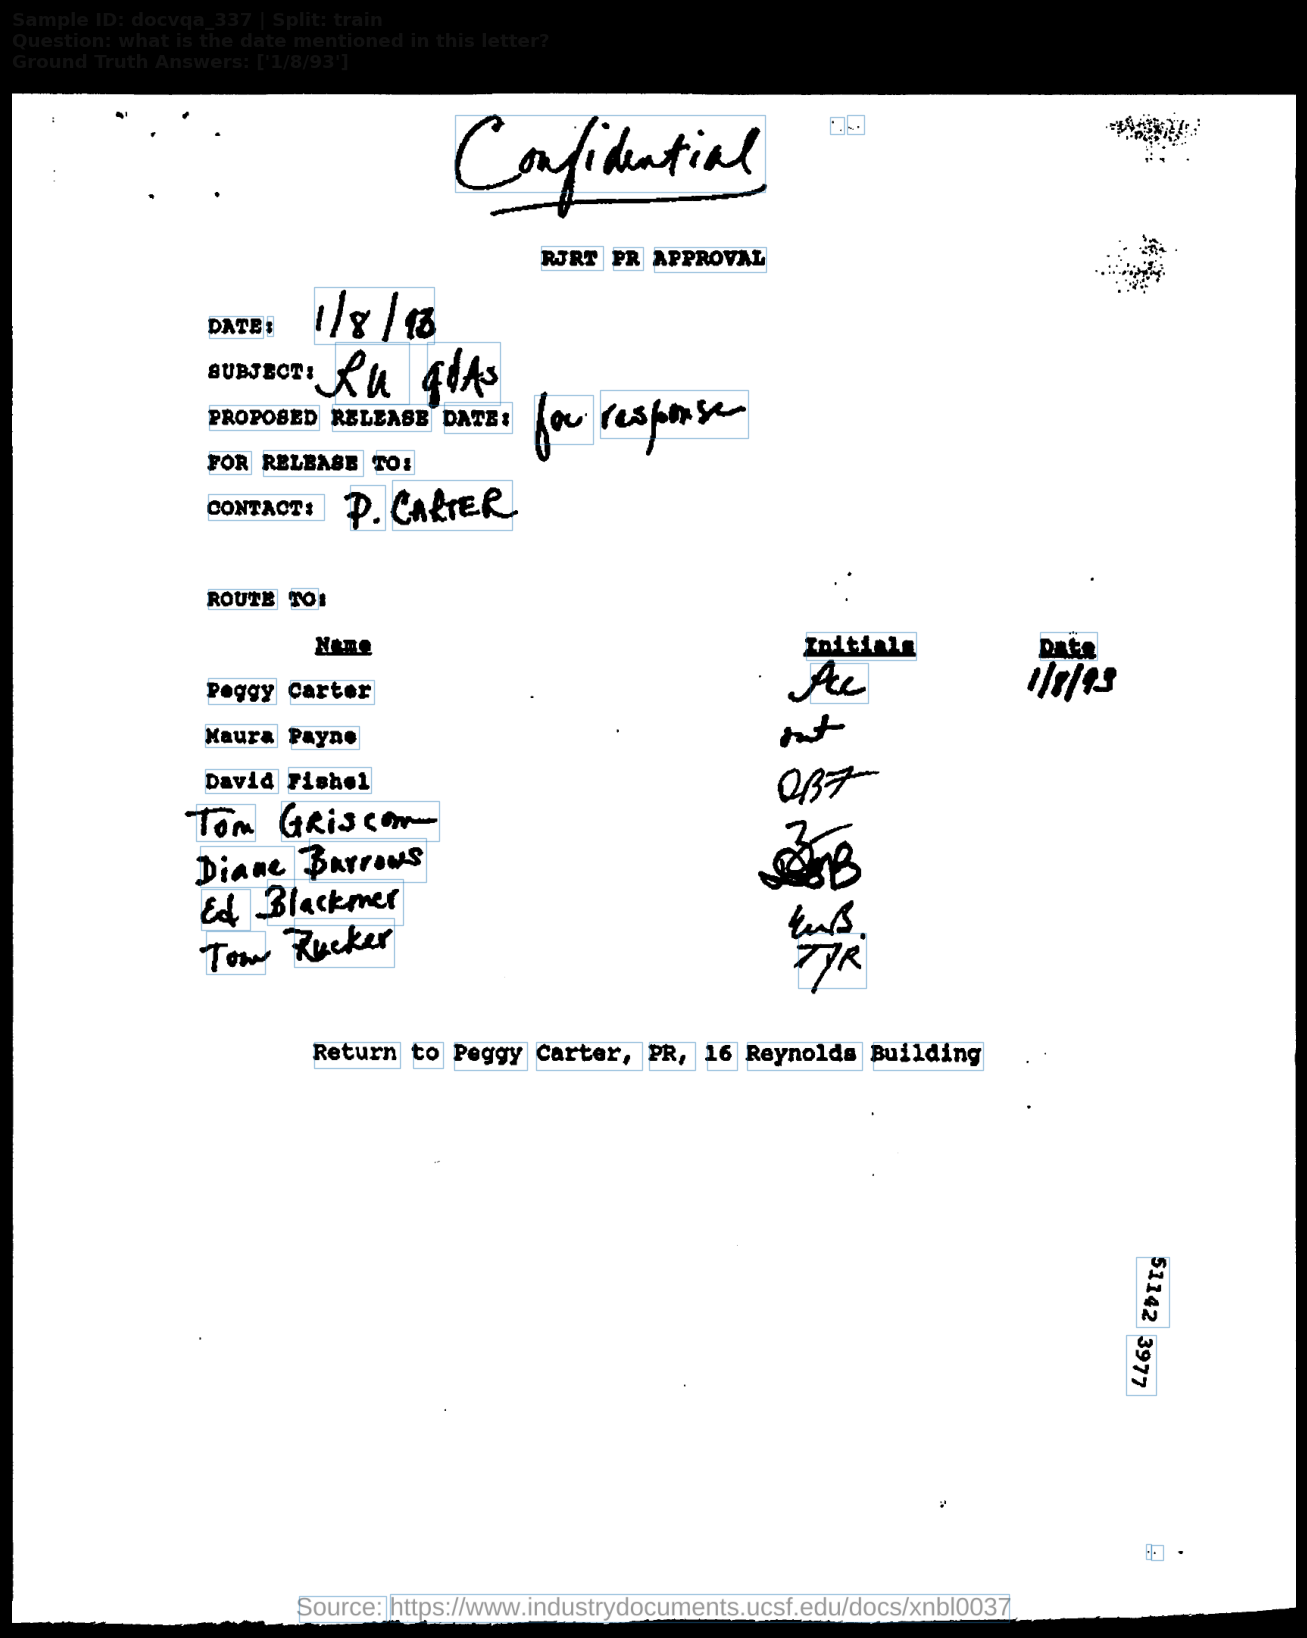

In [6]:
def visualize_vqa_sample(sample: Dict[str, Any], max_display_boxes: int = 150):
    # Decode image
    img_meta = sample.get("image")
    if isinstance(img_meta, dict) and "bytes" in img_meta:
        pil_img = Image.open(io.BytesIO(img_meta["bytes"])).convert("RGB")
    elif isinstance(img_meta, Image.Image):
        pil_img = img_meta.convert("RGB")
    else:
        print("Cannot decode image.")
        return
        
    img_w, img_h = pil_img.size
    boxes = sample.get("ocr_boxes", [])
    tokens = sample.get("ocr_tokens", [])
    answers = [a.lower().strip() for a in sample.get("answers", []) if a]
    
    fig, ax = plt.subplots(figsize=(11, 14), dpi=120)
    ax.imshow(pil_img)
    
    # Plot bounding boxes
    for idx, (box, token) in enumerate(zip(boxes[:max_display_boxes], tokens[:max_display_boxes])):
        ymin, xmin, ymax, xmax = box
        
        # Scale from [0, 1000] back to image pixels
        px_xmin = (xmin / 1000.0) * img_w
        px_xmax = (xmax / 1000.0) * img_w
        px_ymin = (ymin / 1000.0) * img_h
        px_ymax = (ymax / 1000.0) * img_h
        
        width = max(1, px_xmax - px_xmin)
        height = max(1, px_ymax - px_ymin)
        
        # Highlight if token belongs to an answer
        is_answer = any(token.lower().strip() in ans for ans in answers) and len(token.strip()) > 1
        edge_color = "red" if is_answer else "#1f77b4"
        line_width = 2.5 if is_answer else 0.8
        alpha = 0.9 if is_answer else 0.4
        
        rect = patches.Rectangle(
            (px_xmin, px_ymin), width, height,
            linewidth=line_width, edgecolor=edge_color,
            facecolor="none", alpha=alpha
        )
        ax.add_patch(rect)
        
    ax.axis("off")
    title_text = (
        f"Sample ID: {sample.get('sample_id')} | Split: {sample.get('split')}\n"
        f"Question: {sample.get('question')}\n"
        f"Ground Truth Answers: {sample.get('answers')}"
    )
    plt.title(title_text, fontsize=11, pad=15, loc="left", color="#111111", weight="bold")
    plt.tight_layout()
    plt.show()

visualize_vqa_sample(docvqa_sample)

## 6. Cross-Domain Comparative Inspection: DocVQA vs. TextVQA

To understand domain shift (Document Text vs. Scene Text), we compare the sample formats and statistics side by side.

In [7]:
comparison_data = [
    {
        "Domain": "DocVQA (Document)",
        "Sample ID": docvqa_sample.get("sample_id"),
        "Image Dimensions": f"{docvqa_sample.get('image_width')} x {docvqa_sample.get('image_height')}",
        "Question": docvqa_sample.get("question"),
        "Answers Count": len(docvqa_sample.get("answers", [])),
        "Canonical Answer": docvqa_sample.get("canonical_answer"),
        "OCR Tokens Count": len(docvqa_sample.get("ocr_tokens", [])),
    },
    {
        "Domain": "TextVQA (Scene)",
        "Sample ID": textvqa_sample.get("sample_id"),
        "Image Dimensions": f"{textvqa_sample.get('image_width')} x {textvqa_sample.get('image_height')}",
        "Question": textvqa_sample.get("question"),
        "Answers Count": len(textvqa_sample.get("answers", [])),
        "Canonical Answer": textvqa_sample.get("canonical_answer"),
        "OCR Tokens Count": len(textvqa_sample.get("ocr_tokens", [])),
    }
]

pd.DataFrame(comparison_data).T

,0,1
Domain,DocVQA (Document),TextVQA (Scene)
Sample ID,docvqa_337,textvqa_0
Image Dimensions,1695 x 2025,1024 x 730
Question,what is the date mentioned in this letter?,what is the brand of phone?
Answers Count,1,10
Canonical Answer,1/8/93,nokia
OCR Tokens Count,56,2


## 7. In-Depth Sample Exploration: TextVQA Canonical (Scene Text)

We now perform the same granular, multi-step investigation on a **TextVQA Canonical** entry (`textvqa_sample`).
Key scene-text characteristics to examine:
- **Scene Photography**: Natural lighting, camera perspective, arbitrary orientation, and non-planar surfaces.
- **Sparse OCR Token Distribution**: Typically 2-30 scene text tokens versus hundreds of dense document tokens.
- **Multi-Annotator Consensus**: 10 human answer strings per question with soft consensus evaluation.

In [8]:
# 7.1 Field-by-Field Breakdown of TextVQA Sample
inspect_canonical_sample(textvqa_sample, title="TextVQA Canonical Sample")

# Detailed inspection of the 10 ground truth answer annotations
from collections import Counter
ans_counts = Counter(textvqa_sample.get("answers", []))
print("• Answer Distribution across 10 annotators:")
for ans, count in ans_counts.most_common():
    print(f"    - '{ans}': {count} vote(s)")


TEXTVQA CANONICAL SAMPLE: textvqa_0 (scene_text)
• Sample ID        : textvqa_0 (Type: str)
• Question ID      : 0
• Split            : train
• Domain Type      : scene_text
• Question         : 'what is the brand of phone?'
• Question Tokens  : ['what', 'is', 'the', 'brand', 'of', 'phone'] (Count: 6)
• Ground Answers   : ['nokia', 'nokia', 'nokia', 'nokia', 'toshiba', 'nokia', 'nokia', 'nokia', 'nokia', 'nokia']
• Canonical Answer : 'nokia' (Majority Vote)
• Image Format     : JPEG, Mode: RGB, Size: (1024, 730) (W x H)
• Declared Dims    : Width=1024, Height=730
• OCR Tokens Count : 2
• OCR Boxes Count  : 2
  First 5 Tokens   : ['MIA', 'NOKIA']
  First 5 Boxes    : [[430, 321, 460, 352], [458, 327, 487, 377]]
• Metadata Keys    : ['image_classes', 'flickr_original_url', 'exif_transposed']
• Answer Distribution across 10 annotators:
    - 'nokia': 9 vote(s)
    - 'toshiba': 1 vote(s)


### 7.2 OCR Bounding Box Inspection & Coordinate System Verification

We verify that TextVQA bounding boxes strictly conform to the discrete LayoutLM range $[0, 1000]$ format `[ymin, xmin, ymax, xmax]` without degeneracies.

In [ ]:
verify_bounding_boxes(textvqa_sample.get("ocr_boxes", []), textvqa_sample.get("ocr_tokens", []))


Total Bounding Boxes: 2
Coordinate Min: 321, Max: 487
Out-of-bounds coordinates count: 0
Degenerate or inverted vertical boxes (ymin >= ymax): 0
Degenerate or inverted horizontal boxes (xmin >= xmax): 0

Sample OCR Token <-> Box Mappings:
  [00] 'MIA' -> [ymin=430, xmin=321, ymax=460, xmax=352]
  [01] 'NOKIA' -> [ymin=458, xmin=327, ymax=487, xmax=377]


### 7.3 Extractive Grounding Diagnosis (Answer-in-OCR Check)

Checking whether the target answers for the scene image are present as verbatim substrings or single tokens in the OCR token list.

In [ ]:
check_extractive_grounding(textvqa_sample)


Question: what is the brand of phone?
Answers : ['nokia', 'nokia', 'nokia', 'nokia', 'toshiba', 'nokia', 'nokia', 'nokia', 'nokia', 'nokia']
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'toshiba' -> NON-EXTRACTABLE (Generative/Paraphrased) (Single token: False)
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'nokia' -> EXTRACTABLE (Single token: True)
  • 'nokia' -> EXTRACTABLE (Single token: True)


### 7.4 Visualizer: Scene Image with Overlaid OCR Bounding Boxes

We render the scene image, overlaying detected OCR bounding boxes and highlighting the ground-truth target span in red with readable labels.

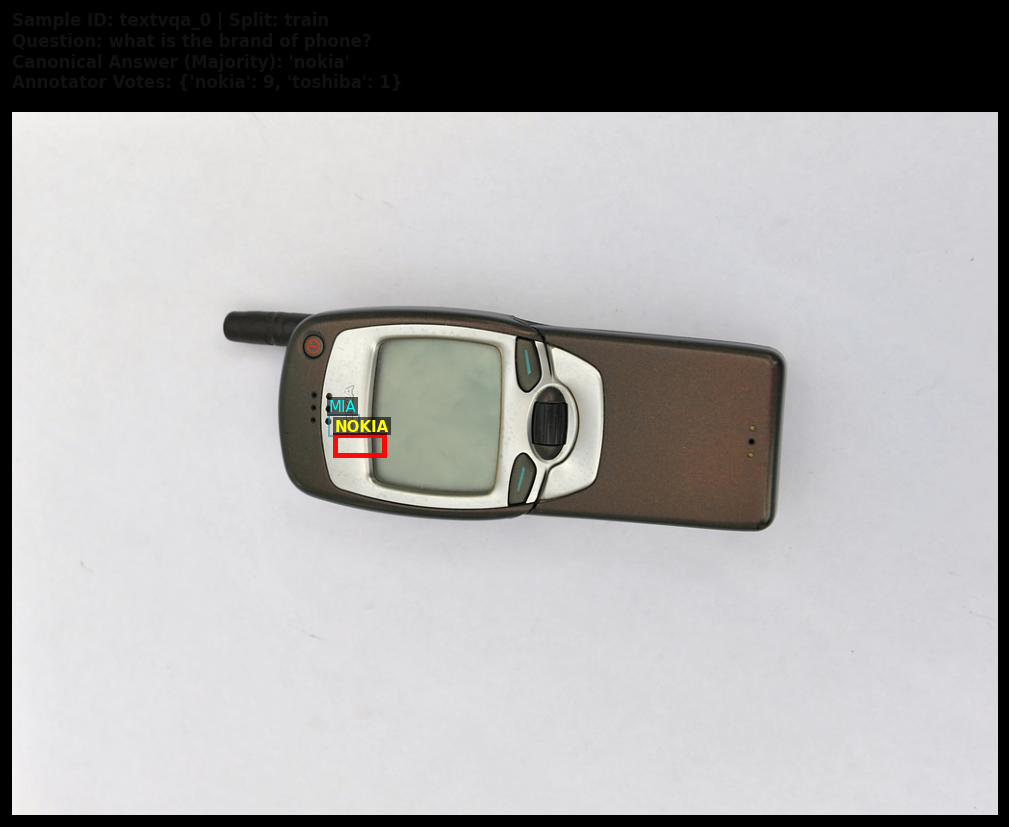

In [11]:
def visualize_textvqa_sample(sample: Dict[str, Any]):
    # Decode image (dict with bytes or PIL)
    img_meta = sample.get("image")
    if isinstance(img_meta, dict) and "bytes" in img_meta:
        pil_img = Image.open(io.BytesIO(img_meta["bytes"])).convert("RGB")
    elif isinstance(img_meta, Image.Image):
        pil_img = img_meta.convert("RGB")
    else:
        print("Cannot decode image.")
        return
        
    img_w, img_h = pil_img.size
    boxes = sample.get("ocr_boxes", [])
    tokens = sample.get("ocr_tokens", [])
    answers = [a.lower().strip() for a in sample.get("answers", []) if a]
    
    # Natural scene images often have wider landscape aspect ratios
    fig, ax = plt.subplots(figsize=(10, 7), dpi=120)
    ax.imshow(pil_img)
    
    for box, token in zip(boxes, tokens):
        ymin, xmin, ymax, xmax = box
        px_xmin = (xmin / 1000.0) * img_w
        px_xmax = (xmax / 1000.0) * img_w
        px_ymin = (ymin / 1000.0) * img_h
        px_ymax = (ymax / 1000.0) * img_h
        
        width = max(1, px_xmax - px_xmin)
        height = max(1, px_ymax - px_ymin)
        
        is_answer = any(token.lower().strip() in ans for ans in answers) and len(token.strip()) > 1
        edge_color = "red" if is_answer else "#1f77b4"
        line_width = 3.0 if is_answer else 1.2
        alpha = 0.95 if is_answer else 0.5
        
        rect = patches.Rectangle(
            (px_xmin, px_ymin), width, height,
            linewidth=line_width, edgecolor=edge_color,
            facecolor="none", alpha=alpha
        )
        ax.add_patch(rect)
        
        # Label OCR token on image
        ax.text(
            px_xmin, max(0, px_ymin - 4),
            token,
            fontsize=9,
            color="yellow" if is_answer else "cyan",
            bbox=dict(facecolor="black", alpha=0.6, pad=1, edgecolor="none"),
            weight="bold" if is_answer else "normal"
        )
        
    ax.axis("off")
    title_text = (
        f"Sample ID: {sample.get('sample_id')} | Split: {sample.get('split')}\n"
        f"Question: {sample.get('question')}\n"
        f"Canonical Answer (Majority): '{sample.get('canonical_answer')}'\n"
        f"Annotator Votes: {dict(Counter(sample.get('answers', []))) }"
    )
    plt.title(title_text, fontsize=10, pad=15, loc="left", color="#111111", weight="bold")
    plt.tight_layout()
    plt.show()

visualize_textvqa_sample(textvqa_sample)


### 7.5 Raw Scene Image (Unannotated Baseline for Direct Comparison)

We display the unmodified raw scene image side-by-side with the OCR-overlaid version to visually evaluate token coverage, font readability, occlusion, and background clutter without bounding box artifacts.

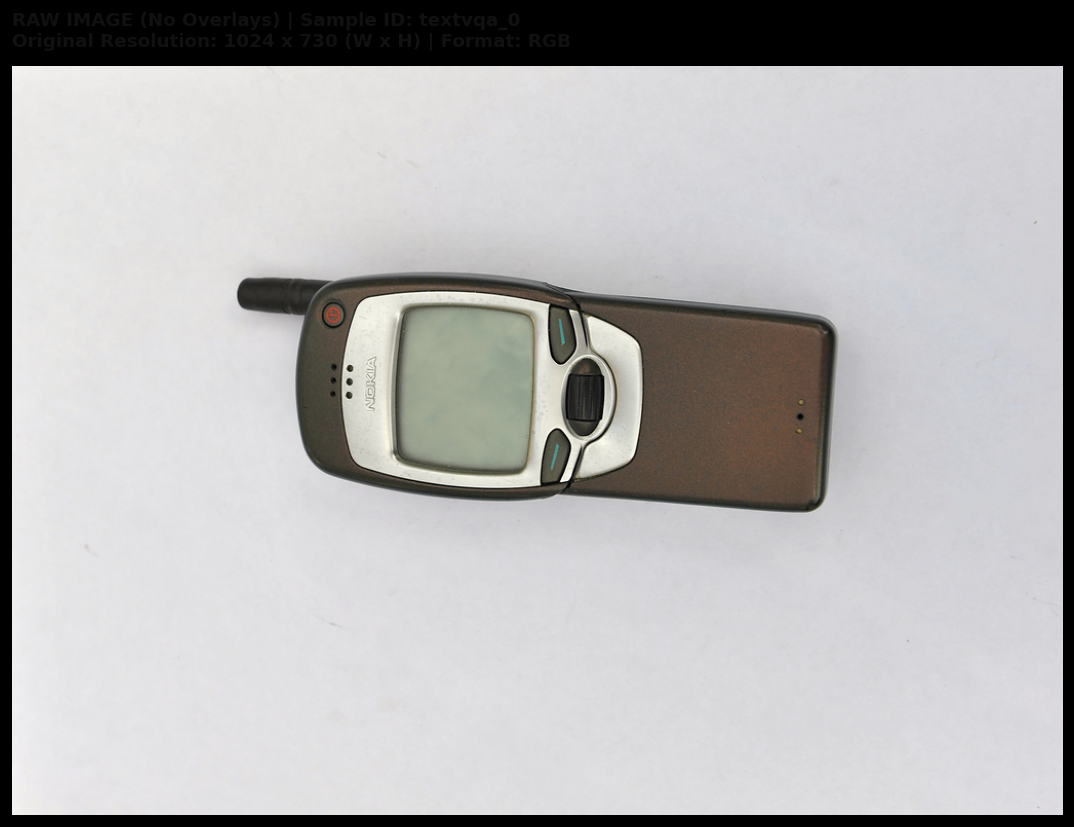

In [12]:
def display_raw_image(sample: Dict[str, Any]):
    img_meta = sample.get("image")
    if isinstance(img_meta, dict) and "bytes" in img_meta:
        pil_img = Image.open(io.BytesIO(img_meta["bytes"])).convert("RGB")
    elif isinstance(img_meta, Image.Image):
        pil_img = img_meta.convert("RGB")
    else:
        print("Cannot decode image.")
        return
        
    fig, ax = plt.subplots(figsize=(10, 7), dpi=120)
    ax.imshow(pil_img)
    ax.axis("off")
    title_text = (
        f"RAW IMAGE (No Overlays) | Sample ID: {sample.get('sample_id')}\n"
        f"Original Resolution: {pil_img.size[0]} x {pil_img.size[1]} (W x H) | Format: {sample.get('image_format', 'RGB')}"
    )
    plt.title(title_text, fontsize=11, pad=12, loc="left", color="#111111", weight="bold")
    plt.tight_layout()
    plt.show()

display_raw_image(textvqa_sample)


###  Note: Spatial Alignment & OCR Bounding Box Nuances in TextVQA

When comparing the annotated visualization of sample `textvqa_0` against the raw image, noticeable spatial discrepancies appear between the recognized token (`NOKIA`), the bounding box, and the physical text on the device. This occurs due to three compounding reasons:

1. **Visualization Readability Offset (`px_ymin - 4`)**:
   - In `visualize_textvqa_sample`, the token label is deliberately placed slightly above the top edge of the box (`max(0, px_ymin - 4)`) with a dark background pad. This avoids painting over or occluding the underlying image pixels.

2. **Physical Scene Rotation (90° Tilt)**:
   - The phone is lying horizontally (landscape). However, the embossed `"NOKIA"` lettering beside the speaker holes was molded for portrait orientation, making the characters run vertically (top-to-bottom) in camera coordinates.

3. **Axis-Aligned Bounding Box (AABB) & Upstream Detector Bias**:
   - LayoutLM and TextVQA format bounding boxes as 4-coordinate non-rotated rectangles `[ymin, xmin, ymax, xmax]`, without support for an angle parameter ($\theta$) or 4-point arbitrary polygons.
   - The pre-extracted OCR engine (Facebook Rosetta OCR) was trained primarily on standard horizontal scene text. Confronted with low-contrast, embossed, 90°-rotated lettering, it predicted a wide horizontal candidate box that only partially captured the bottom tail of the word and fragmented the reading into `'MIA'` and `'NOKIA'`.


## 8. Deep-Dive Inspection: Question and Answer (Q&A) Data Structures

Across visual question answering datasets, Question and Answer formats differ significantly in how annotations were gathered and modeled.

### Key Structural Differences between DocVQA and TextVQA:
- **Question Formats**:
  - `question` (`str`): The natural language query string.
  - `question_tokens` (`List[str]`): Pre-tokenized word array. Note tokenization differences (e.g. keeping punctuation attached vs. stripped).
- **Answer Formats**:
  - `answers` (`List[str]`):
    - **DocVQA**: Typically contains 1 to 3 acceptable ground-truth alias strings (spans directly extracted from document text or valid synonyms).
    - **TextVQA**: Contains exactly **10 crowd-sourced annotations** collected from 10 distinct annotators (e.g., `['nokia', 'nokia', ..., 'toshiba']`), reflecting human annotator variance and typos.
  - `canonical_answer` (`str`): Unified single ground truth derived via majority vote or consensus for standard evaluation.
- **Evaluation Metric Implication**:
  - DocVQA uses **Average Normalized Levenshtein Similarity (ANLS)**.
  - TextVQA uses **VQA Accuracy**: $\min(1.0, \frac{\text{Number of humans giving answer}}{3})$.
- **Domain Metadata**:
  - DocVQA includes document-level tracking (`docId`, `ucsf_document_id`, `question_types`).
  - TextVQA includes scene-level context (`image_classes`, `flickr_original_url`, `exif_transposed`).


In [13]:
from collections import Counter
import pandas as pd

def inspect_qa_structure(sample: Dict[str, Any], domain_name: str):
    print('=' * 80)
    print(f'Q&A STRUCTURE INSPECTION: {domain_name.upper()} (Sample ID: {sample.get("sample_id")})')
    print('=' * 80)
    
    # Question inspection
    q_str = sample.get('question')
    q_toks = sample.get('question_tokens', [])
    print(f'1. QUESTION SPECIFICATION:')
    print(f'   - Raw Question (str)      : "{q_str}"')
    print(f'   - Question Tokens (List)  : {q_toks}')
    print(f'   - Token Count             : {len(q_toks)}')
    print(f'   - Character Length        : {len(q_str) if q_str else 0} chars')
    
    # Answer inspection
    answers = sample.get('answers', [])
    canon_ans = sample.get('canonical_answer')
    ans_counter = Counter(answers)
    
    print(f'\n2. ANSWER SPECIFICATION:')
    print(f'   - Raw Answers List        : {answers}')
    print(f'   - Total Annotations Count : {len(answers)}')
    print(f'   - Unique Variations       : {len(ans_counter)} distinct string(s)')
    print(f'   - Canonical / Majority Ans: "{canon_ans}"')
    
    print(f'   - Frequency Breakdown     :')
    for ans, count in ans_counter.most_common():
        pct = (count / len(answers)) * 100 if answers else 0
        print(f'       * "{ans}": {count} vote(s) ({pct:.1f}%)')
        
    # VQA Score simulation (standard 10-vote VQA metric)
    if len(answers) == 10:
        vqa_acc = min(1.0, ans_counter.get(canon_ans, 0) / 3.0)
        print(f'   - TextVQA Accuracy Score  : {vqa_acc * 100:.1f}% for predicting canonical "{canon_ans}"')
    
    # Domain-specific Metadata
    raw_meta = sample.get('metadata')
    meta_dict = json.loads(raw_meta) if isinstance(raw_meta, str) else (raw_meta or {})
    print(f'\n3. AUXILIARY Q&A METADATA:')
    for k, v in meta_dict.items():
        print(f'   - {k:<22}: {v}')
    print('=' * 80 + '\n')

# Run inspection on both domain samples
inspect_qa_structure(docvqa_sample, 'DocVQA (Document Text)')
inspect_qa_structure(textvqa_sample, 'TextVQA (Scene Text)')


Q&A STRUCTURE INSPECTION: DOCVQA (DOCUMENT TEXT) (Sample ID: docvqa_337)
1. QUESTION SPECIFICATION:
   - Raw Question (str)      : "what is the date mentioned in this letter?"
   - Question Tokens (List)  : ['what', 'is', 'the', 'date', 'mentioned', 'in', 'this', 'letter?']
   - Token Count             : 8
   - Character Length        : 42 chars

2. ANSWER SPECIFICATION:
   - Raw Answers List        : ['1/8/93']
   - Total Annotations Count : 1
   - Unique Variations       : 1 distinct string(s)
   - Canonical / Majority Ans: "1/8/93"
   - Frequency Breakdown     :
       * "1/8/93": 1 vote(s) (100.0%)

3. AUXILIARY Q&A METADATA:
   - question_types        : ['handwritten', 'form']
   - docId                 : 279
   - ucsf_document_id      : xnbl0037
   - ucsf_document_page_no : 1

Q&A STRUCTURE INSPECTION: TEXTVQA (SCENE TEXT) (Sample ID: textvqa_0)
1. QUESTION SPECIFICATION:
   - Raw Question (str)      : "what is the brand of phone?"
   - Question Tokens (List)  : ['what', 'is', 't

In [14]:
# Side-by-side Q&A Structure Comparison Table
qa_comparison = [
    {
        "Dimension": "Question String",
        "DocVQA (Document)": f'"{docvqa_sample.get("question")}"',
        "TextVQA (Scene)": f'"{textvqa_sample.get("question")}"'
    },
    {
        "Dimension": "Question Tokens Count",
        "DocVQA (Document)": len(docvqa_sample.get("question_tokens", [])),
        "TextVQA (Scene)": len(textvqa_sample.get("question_tokens", []))
    },
    {
        "Dimension": "Answers Annotation Count",
        "DocVQA (Document)": f'{len(docvqa_sample.get("answers", []))} ground-truth span(s)',
        "TextVQA (Scene)": f'{len(textvqa_sample.get("answers", []))} crowd-worker votes'
    },
    {
        "Dimension": "Canonical Answer",
        "DocVQA (Document)": f'"{docvqa_sample.get("canonical_answer")}"',
        "TextVQA (Scene)": f'"{textvqa_sample.get("canonical_answer")}"'
    },
    {
        "Dimension": "Answer Disagreement / Entropy",
        "DocVQA (Document)": "Low (exact value matches document span)",
        "TextVQA (Scene)": f'{len(set(textvqa_sample.get("answers", [])))} unique responses across 10 annotators'
    },
    {
        "Dimension": "Evaluation Paradigm",
        "DocVQA (Document)": "ANLS (Average Normalized Levenshtein Similarity)",
        "TextVQA (Scene)": "VQA Accuracy (min(1.0, votes / 3))"
    }
]

df_qa = pd.DataFrame(qa_comparison).set_index("Dimension")
display(df_qa)


,DocVQA (Document),TextVQA (Scene)
Dimension,,
Question String,"""what is the date mentioned in this letter?""","""what is the brand of phone?"""
Question Tokens Count,8,6
Answers Annotation Count,1 ground-truth span(s),10 crowd-worker votes
Canonical Answer,"""1/8/93""","""nokia"""
Answer Disagreement / Entropy,Low (exact value matches document span),2 unique responses across 10 annotators
Evaluation Paradigm,ANLS (Average Normalized Levenshtein Similarity),"VQA Accuracy (min(1.0, votes / 3))"
